# E-commerce Sales and Profit Analysis (2023)

**Questions:** where does revenue and profit come from, how does it move through the year, and are shipping and
discounts helping or hurting? Built on the e-commerce dataset from my Digital Skola *Alchemist Project*.

**Data:** 51,282 order lines from 2023 across 4 product categories and 14 regions (`data/ecommerce_orders.csv.gz`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/ecommerce_orders.csv.gz", parse_dates=["Order Date", "Ship Date"])
print(df.shape, "| period:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0].to_string())
df = df.dropna(subset=["Customer ID", "Region"])
print("Region values with a typo:", df.loc[df["Region"] == "4orth", "Region"].count())
df["Region"] = df["Region"].replace({"4orth": "North"})   # data-entry typo
df["month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
kpi = pd.Series({
    "Revenue": df["Sales"].sum(),
    "Profit": df["Profit"].sum(),
    "Profit margin %": df["Profit"].sum() / df["Sales"].sum() * 100,
    "Orders": df["Order Id"].nunique(),
    "Customers": df["Customer ID"].nunique(),
    "Avg delivery days": df["Aging"].mean(),
}).round(1)
kpi

(51282, 21) | period: 2023-01-01 to 2023-12-31
Missing values:
 Customer ID    1
Region         1
Region values with a typo: 1


,0
Revenue,8021532.0
Profit,3729063.1
Profit margin %,46.5
Orders,51280.0
Customers,51280.0
Avg delivery days,5.3


Best month: December ($693,073) | weakest: February ($609,990)
Best month is 1.1x the weakest


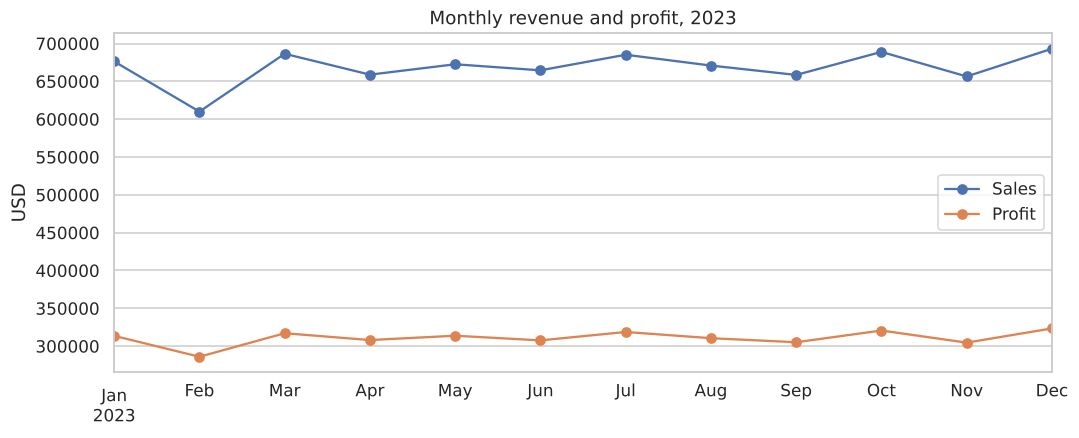

In [3]:
monthly = df.groupby("month")[["Sales", "Profit"]].sum()
ax = monthly.plot(figsize=(11, 4), marker="o")
ax.set(title="Monthly revenue and profit, 2023", xlabel="", ylabel="USD")
best, worst = monthly["Sales"].idxmax(), monthly["Sales"].idxmin()
print(f"Best month: {best:%B} (${monthly['Sales'].max():,.0f}) | weakest: {worst:%B} (${monthly['Sales'].min():,.0f})")
print(f"Best month is {monthly['Sales'].max() / monthly['Sales'].min():.1f}x the weakest")

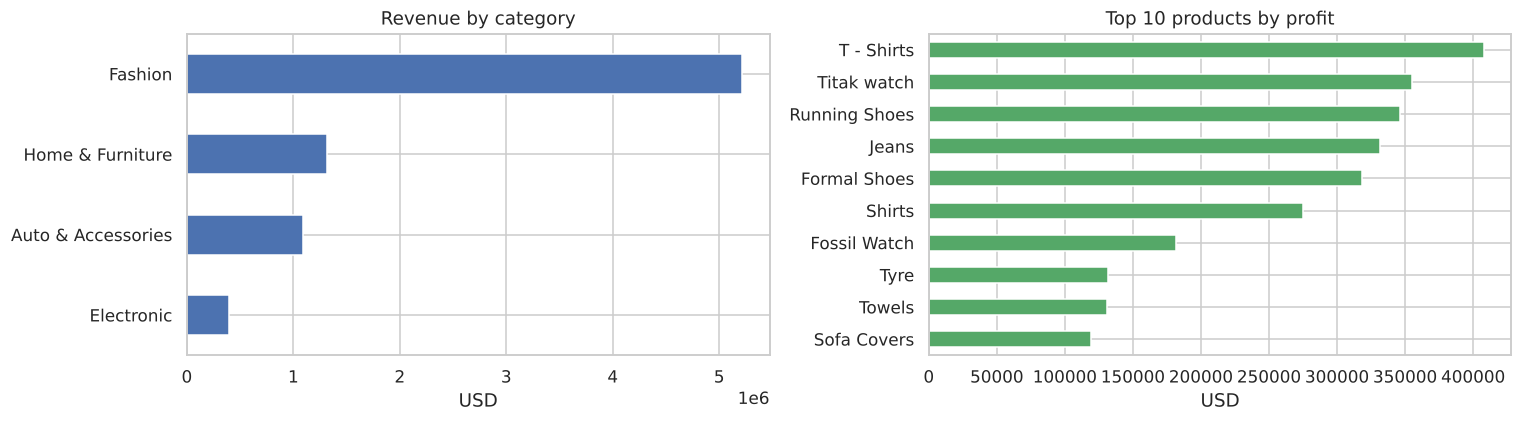

,revenue,profit,orders,margin_%,revenue_share_%
Product Category,,,,,
Fashion,5212097.0,2483955.2,30775,47.7,65.0
Home & Furniture,1319407.0,587614.3,10309,44.5,16.4
Auto & Accessories,1095290.0,483303.0,7495,44.1,13.7
Electronic,394738.0,174190.6,2701,44.1,4.9


In [4]:
cat = (df.groupby("Product Category")
         .agg(revenue=("Sales", "sum"), profit=("Profit", "sum"), orders=("Order Id", "nunique")))
cat["margin_%"] = cat["profit"] / cat["revenue"] * 100
cat["revenue_share_%"] = cat["revenue"] / cat["revenue"].sum() * 100
top_products = (df.groupby("Product")["Profit"].sum().sort_values(ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cat["revenue"].sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set(title="Revenue by category", xlabel="USD", ylabel="")
top_products.sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set(title="Top 10 products by profit", xlabel="USD", ylabel="")
plt.tight_layout()
cat.sort_values("revenue", ascending=False).round(1)

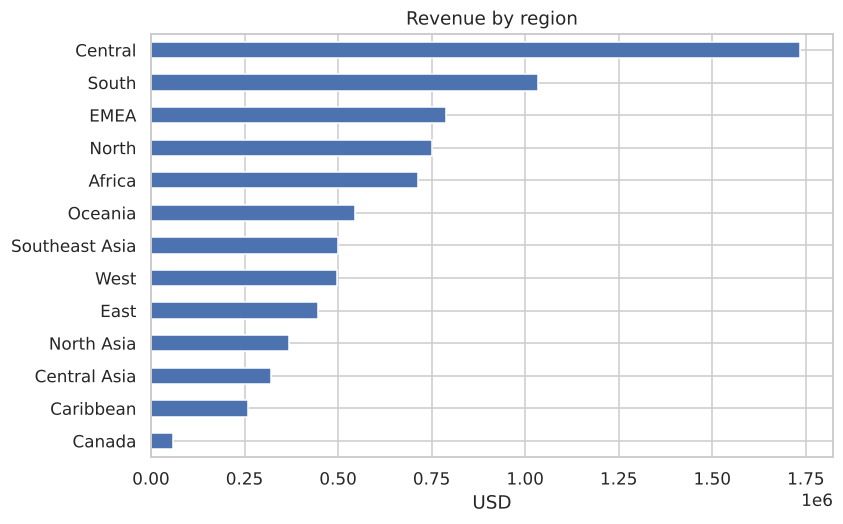

,revenue,profit,margin_pct
Region,,,
Central,1735650.0,804077.5,46.3
South,1034672.0,479079.9,46.3
EMEA,788072.0,368570.7,46.8
North,749961.0,349014.3,46.5
Africa,713020.0,332166.0,46.6
Oceania,544616.0,253577.6,46.6
Southeast Asia,500712.0,235473.4,47.0
West,497432.0,231775.8,46.6
East,446468.0,206694.5,46.3


In [5]:
region = (df.groupby("Region").agg(revenue=("Sales", "sum"), profit=("Profit", "sum"))
            .assign(margin_pct=lambda x: x["profit"] / x["revenue"] * 100)
            .sort_values("revenue", ascending=False))
ax = region["revenue"].sort_values().plot(kind="barh", figsize=(8, 5), color="#4C72B0")
ax.set(title="Revenue by region", xlabel="USD", ylabel="")
region.round(1)

In [6]:
ship = df.groupby("Ship Mode").agg(lines=("Order Id", "size"), avg_delivery_days=("Aging", "mean"),
                                   avg_shipping_cost=("Shipping Cost", "mean"),
                                   margin_pct=("Profit", lambda s: s.sum() / df.loc[s.index, "Sales"].sum() * 100))
df["discount_band"] = pd.cut(df["Discount"], [0, 0.02, 0.03, 0.04, 0.05], labels=["1-2%", "3%", "4%", "5%"])
disc = df.groupby("discount_band", observed=True).apply(
    lambda g: pd.Series({"lines": len(g), "avg_quantity": g["Quantity"].mean(),
                         "margin_pct": g["Profit"].sum() / g["Sales"].sum() * 100}), include_groups=False)
print("Shipping mode:")
print(ship.round(2).to_string())
print("\nDiscount level:")
print(disc.round(2).to_string())

Shipping mode:
                lines  avg_delivery_days  avg_shipping_cost  margin_pct
Ship Mode                                                              
First Class      7495               5.54               6.45       44.13
Same Day         2701               1.00               6.46       44.13
Second Class    10309               5.45               5.70       44.54
Standard Class  30775               5.49               8.07       47.66

Discount level:
                 lines  avg_quantity  margin_pct
discount_band                                   
1-2%           20498.0          2.98       50.25
3%             10357.0          3.01       46.79
4%             10253.0          3.00       43.89
5%             10172.0          3.01       41.16


**Findings and recommendations**

* **Fashion is the business.** It brings 65% of revenue at the best margin (47.7%), so protect stock and marketing spend there first.
* **Revenue is steady through the year.** December, the best month, is only about 14% above February, the weakest. Growth has to come from more customers and orders, not from seasonal peaks.
* **Discounts give away margin without adding volume.** The average quantity per order is about 3.0 at every discount level, while the margin falls from 50% at 1–2% discounts to 41% at 5%. Recommendation: cap routine discounts at 2% and test targeted offers instead.
* **Same Day delivery arrives in 1 day versus about 5.5 days for other modes, at a similar shipping cost**, which makes it a strong candidate for premium positioning.
* **Data quality:** one region label had a typo ("4orth") and was corrected to North. One row with a missing customer and region was removed.

*Note:* the dataset is a teaching dataset with simulated orders, so the patterns illustrate the method rather than a real company.